# Phase 1 | Noise Schedule Verification
### Foundation Models and Generative AI · InstructPix2Pix + SEN12MS

We create this to reconstructs the checkpoint's *scaled-linear* beta schedule, declares the cumulative retention coefficient as $\theta_t=\bar\alpha_t$, and applies the declared power $x=2.00$.

**Produces when run:**

- `Phase1_Schedule_Full.csv` (all 1,000 diffusion steps)
- `Phase1_Schedule_Sanity.csv` (five selected timesteps)
- `Phase1_Schedule_Comparison.png` (native vs powered $\bar\alpha_t$ on the **same** axes)
- `Phase1_LogSNR_Comparison.png` (how the log-SNR changes)

All output files are saved in `phase1_schedule_outputs/`, relative to the notebook's working directory.

> **Scope:** A successful run verifies the stated mathematical schedule values and produces Phase 1 evidence. It **does not** load model weights, download SEN12MS, fine-tune InstructPix2Pix, check training artifacts, or establish that the dataset was absent from pretraining. Those are separate requirements/actions.

**Source of the declared values:** (InstructPix2Pix checkpoint `timbrooks/instruct-pix2pix`; `beta_start=0.00085`, `beta_end=0.012`, `beta_schedule=scaled_linear`, 1000 training timesteps, and $x=2.00$).

## 1. Parameters, notation, and expected identities

The native *scaled-linear* beta schedule is constructed by interpolating between the **square roots** of the beta endpoints and squaring afterward:

$$
\beta_t=\left[\sqrt{\beta_{\rm start}} + \frac{t-1}{T-1}\left(\sqrt{\beta_{\rm end}}-\sqrt{\beta_{\rm start}}\right)\right]^2,\quad t=1,\ldots,T.
$$

$$
\alpha_t=1-\beta_t, \quad \bar\alpha_t=\prod_{s=1}^{t}\alpha_s, \quad \theta_t = \bar\alpha_t.
$$

For Run B, our declared schedule power is applied **elementwise to the cumulative** $\bar\alpha_t$:

$$
\bar\alpha_t^{(B)}=(\bar\alpha_t^{(A)})^x,
\quad \alpha_t^{(B)}=(\alpha_t^{(A)})^x,
\quad \beta_t^{(B)}=1-(1-\beta_t^{(A)})^x.
$$

Signal-to-noise ratio for the direct noising distribution is

$$
q(x_t|x_0)=\mathcal N\!\left(\sqrt{\bar\alpha_t}x_0,(1-\bar\alpha_t)I\right),
\qquad \mathrm{SNR}_t=\frac{\bar\alpha_t}{1-\bar\alpha_t}.
$$

With $0<\bar\alpha_t<1$ and $x>1$, the powered cumulative coefficient and its SNR are both lower. **This is specific to choosing $\theta_t=\bar\alpha_t$** and it must not be confused with directly applying $\beta_t^x$.

In [1]:
from pathlib import Path
import csv
import math
import numpy as np
import matplotlib.pyplot as plt

OUTPUT_DIR = Path.cwd() / "phase1_schedule_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {OUTPUT_DIR.resolve()}")

Output directory: /Users/praveenkumar/Documents/mtech/FMGAI-Assignment/fmgai-assignment-1-model-evaluation/phase1_schedule_outputs


## 2. Freeze the declared values

Change these only if the group officially revises the Phase 1 declaration. They must agree with what you submit.

In [2]:
# Parameters transcribed from our Phase 1 declaration.
NUM_TRAIN_TIMESTEPS = 1000
BETA_START = 0.00085
BETA_END = 0.012
BETA_SCHEDULE = "scaled_linear"
NOISE_POWER = 2.00
SELECTED_TIMESTEPS = (1, 250, 500, 750, 1000)

assert NUM_TRAIN_TIMESTEPS >= 5
assert 1.5 < NOISE_POWER < 3.0, "Exponent must be  between 1.5 and 3.0"
assert f"{NOISE_POWER:.2f}" == "2.00"
assert 0 < BETA_START < BETA_END < 1
assert BETA_SCHEDULE == "scaled_linear"
print("Declared exponent:", f"{NOISE_POWER:.2f}")

Declared exponent: 2.00


## 3. Construct Run A and Run B schedules

Array index `0` corresponds to mathematical timestep $t=1$. The output CSV reports **1-based** timesteps.

In [3]:
# Float64 provides stable reproducible schedule calculations.
t = np.arange(1, NUM_TRAIN_TIMESTEPS + 1, dtype=np.int64)
beta_A = np.linspace(
    np.sqrt(BETA_START), np.sqrt(BETA_END), NUM_TRAIN_TIMESTEPS,
    dtype=np.float64
) ** 2
alpha_A = 1.0 - beta_A
alpha_bar_A = np.cumprod(alpha_A)

# Power is applied to theta_t = cumulative alpha, not beta.
alpha_bar_B = alpha_bar_A ** NOISE_POWER
alpha_B = alpha_A ** NOISE_POWER
beta_B = 1.0 - alpha_B

snr_A = alpha_bar_A / (1.0 - alpha_bar_A)
snr_B = alpha_bar_B / (1.0 - alpha_bar_B)
ln_snr_A = np.log(snr_A)
ln_snr_B = np.log(snr_B)

print(f"Run A final alpha-bar: {alpha_bar_A[-1]:.9f}")
print(f"Run B final alpha-bar: {alpha_bar_B[-1]:.9f}")

Run A final alpha-bar: 0.004660099
Run B final alpha-bar: 0.000021717


## 4. Run mathematical checks


In [4]:
# 1. Native and derived coefficients are valid at every step.
assert np.all(np.isfinite(beta_A)) and np.all((beta_A > 0) & (beta_A < 1))
assert np.all((alpha_A > 0) & (alpha_A < 1))
assert np.all((alpha_bar_A > 0) & (alpha_bar_A < 1))
assert np.all((beta_B > 0) & (beta_B < 1))
assert np.all((alpha_B > 0) & (alpha_B < 1))
assert np.all((alpha_bar_B > 0) & (alpha_bar_B < 1))

# 2. Both constructions of the powered cumulative schedule agree.
assert np.allclose(
    np.cumprod(1.0 - beta_B), alpha_bar_B,
    rtol=1e-11, atol=1e-14
), "Inconsistent powered beta and powered alpha-bar"

# 3. Native scheduler bounds and expected direction of the change.
assert np.isclose(beta_A[0], BETA_START, rtol=0, atol=1e-15)
assert np.isclose(beta_A[-1], BETA_END, rtol=0, atol=1e-15)
assert np.all(alpha_bar_B < alpha_bar_A)
assert np.all(snr_B < snr_A)
assert np.all(np.diff(alpha_bar_A) < 0)
assert np.all(np.diff(alpha_bar_B) < 0)

# 4. Sanity checks for the declared reference values (rounded).
assert np.isclose(alpha_bar_A[-1], 0.004660099, atol=1e-9)
assert np.isclose(alpha_bar_B[-1], 0.000021717, atol=1e-9)
print("PASS: native bounds, power identity, monotonicity, SNR direction, reference endpoints")

PASS: native bounds, power identity, monotonicity, SNR direction, reference endpoints


## 5. Export both CSV files

In [5]:
columns = [
    "t", "beta_A", "beta_B", "alpha_A", "alpha_B",
    "alpha_bar_A", "alpha_bar_B", "snr_A", "snr_B",
    "ln_snr_A", "ln_snr_B",
]
arrays = [
    t, beta_A, beta_B, alpha_A, alpha_B,
    alpha_bar_A, alpha_bar_B, snr_A, snr_B,
    ln_snr_A, ln_snr_B,
]

full_csv = OUTPUT_DIR / "Phase1_Schedule_Full.csv"
with full_csv.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(columns)
    for row in zip(*arrays):
        writer.writerow([int(row[0])] + [f"{v:.12g}" for v in row[1:]])

sanity_csv = OUTPUT_DIR / "Phase1_Schedule_Sanity.csv"
with sanity_csv.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["t", "beta_A", "beta_B", "alpha_bar_A", "alpha_bar_B", "ln_snr_A", "ln_snr_B"])
    for step in SELECTED_TIMESTEPS:
        i = step - 1
        writer.writerow([
            step, f"{beta_A[i]:.9f}", f"{beta_B[i]:.9f}",
            f"{alpha_bar_A[i]:.9f}", f"{alpha_bar_B[i]:.9f}",
            f"{ln_snr_A[i]:.6f}", f"{ln_snr_B[i]:.6f}",
        ])

print("Saved:", full_csv.name, "(1,000 rows)")
print("Saved:", sanity_csv.name, "(5 rows)")
print("\n           t   alpha_bar_A    alpha_bar_B      lnSNR_A      lnSNR_B")
for step in SELECTED_TIMESTEPS:
    i = step - 1
    print(f"{step:>12d}   {alpha_bar_A[i]:>11.6f}   {alpha_bar_B[i]:>12.7f}   {ln_snr_A[i]:>10.3f}   {ln_snr_B[i]:>10.3f}")

Saved: Phase1_Schedule_Full.csv (1,000 rows)
Saved: Phase1_Schedule_Sanity.csv (5 rows)

           t   alpha_bar_A    alpha_bar_B      lnSNR_A      lnSNR_B
           1      0.999150      0.9983007        7.069        6.376
         250      0.675432      0.4562089        0.733       -0.176
         500      0.277670      0.0771004       -0.956       -2.482
         750      0.056623      0.0032062       -2.813       -5.739
        1000      0.004660      0.0000217       -5.364      -10.737


## 6. Comparison

This figure plots $\{\theta_t\}$ and $\{\theta_t^x\}$ against $t$ on **the same axes**, as requested by the instructor. We use a logarithmic vertical axis to retain detail at late timesteps.

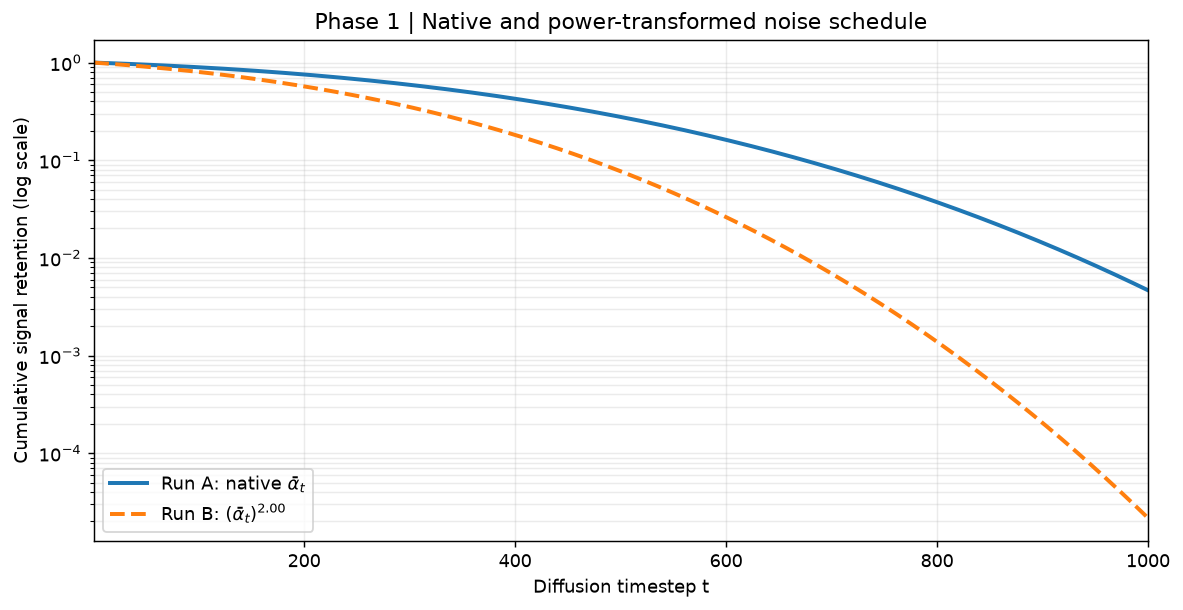

Saved: /Users/praveenkumar/Documents/mtech/FMGAI-Assignment/fmgai-assignment-1-model-evaluation/phase1_schedule_outputs/Phase1_Schedule_Comparison.png


In [6]:
fig, ax = plt.subplots(figsize=(9.2, 4.8), dpi=130)
ax.plot(t, alpha_bar_A, linewidth=2.2, label=r"Run A: native $\bar{\alpha}_t$")
ax.plot(t, alpha_bar_B, linewidth=2.2, linestyle="--", label=r"Run B: $(\bar{\alpha}_t)^{2.00}$")
ax.set_yscale("log")
ax.set_xlim(1, NUM_TRAIN_TIMESTEPS)
ax.set_xlabel("Diffusion timestep t")
ax.set_ylabel("Cumulative signal retention (log scale)")
ax.set_title("Phase 1 | Native and power-transformed noise schedule")
ax.grid(alpha=0.25, which="both")
ax.legend(loc="lower left")
fig.tight_layout()
schedule_png = OUTPUT_DIR / "Phase1_Schedule_Comparison.png"
fig.savefig(schedule_png, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", schedule_png.resolve())

## 7. Analytical SNR

Below figure helps interpret why powered $\bar\alpha_t$ corresponds to lower signal retention and lower SNR.

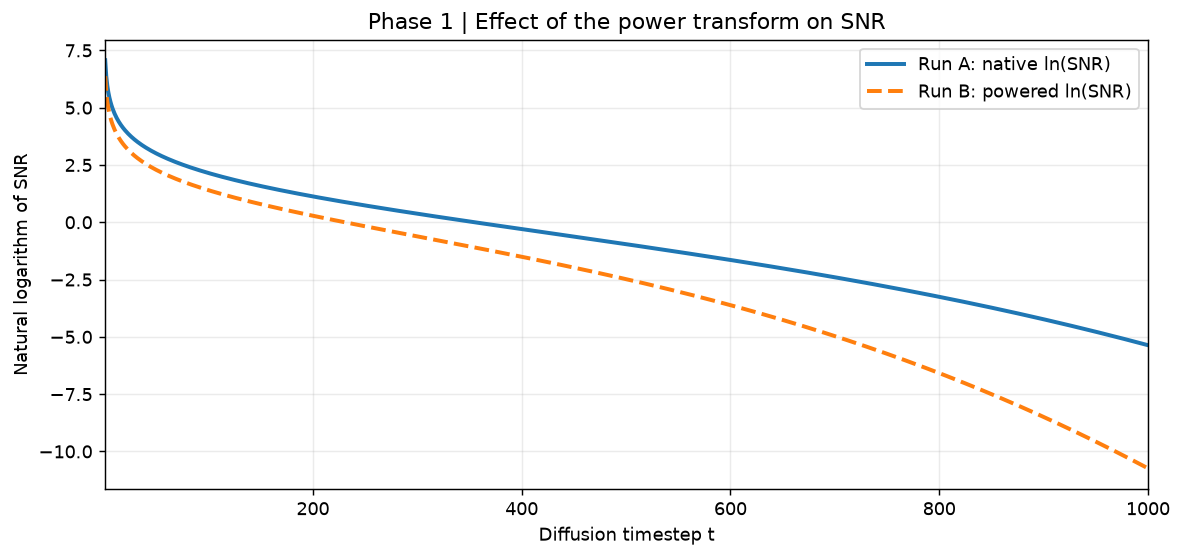

Saved: /Users/praveenkumar/Documents/mtech/FMGAI-Assignment/fmgai-assignment-1-model-evaluation/phase1_schedule_outputs/Phase1_LogSNR_Comparison.png


In [7]:
fig, ax = plt.subplots(figsize=(9.2, 4.4), dpi=130)
ax.plot(t, ln_snr_A, linewidth=2.2, label="Run A: native ln(SNR)")
ax.plot(t, ln_snr_B, linewidth=2.2, linestyle="--", label="Run B: powered ln(SNR)")
ax.set_xlim(1, NUM_TRAIN_TIMESTEPS)
ax.set_xlabel("Diffusion timestep t")
ax.set_ylabel("Natural logarithm of SNR")
ax.set_title("Phase 1 | Effect of the power transform on SNR")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
snr_png = OUTPUT_DIR / "Phase1_LogSNR_Comparison.png"
fig.savefig(snr_png, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", snr_png.resolve())

## 8. Final output

Every listed file must exist and have nonzero size. These generated outputs are **supporting math evidence**, not evidence that any model fine-tuning occurred.

In [8]:
required_files = [full_csv, sanity_csv, schedule_png, snr_png]
for path in required_files:
    assert path.exists() and path.stat().st_size > 0, f"Missing or empty: {path.name}"
    print(f"OK  {path.name:36s} {path.stat().st_size:>10,} bytes")

with full_csv.open(newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))
assert len(rows) == NUM_TRAIN_TIMESTEPS
assert [int(rows[0]["t"]), int(rows[-1]["t"])] == [1, NUM_TRAIN_TIMESTEPS]
print("\nALL CHECKS PASSED. Use the schedule image and sanity table in the declaration as needed.")

OK  Phase1_Schedule_Full.csv                159,387 bytes
OK  Phase1_Schedule_Sanity.csv                  421 bytes
OK  Phase1_Schedule_Comparison.png          107,285 bytes
OK  Phase1_LogSNR_Comparison.png             96,228 bytes

ALL CHECKS PASSED. Use the schedule image and sanity table in the declaration as needed.
